# Matplotlib

In [1]:
import matplotlib.pyplot as plt

### Basic charts

![](https://res.cloudinary.com/codecrucks/image/upload/c_scale,w_700,h_327,dpr_2/f_webp,q_auto/v1648958444/chart-types.png?_i=AA)

### Chart selection roadmap

![](http://blog.atkcg.ru/wp-content/uploads/2015/07/1-%D0%B9-%D1%81%D0%BB%D0%B0%D0%B9%D0%B41.jpg)

Из чего состоит график:

![image.png](https://matplotlib.org/stable/_images/sphx_glr_anatomy_001.png)

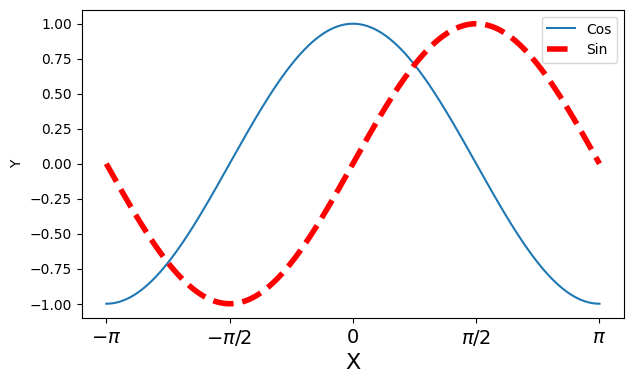

In [2]:
import numpy as np

plt.figure(figsize=(7, 4))
X = np.linspace(-np.pi, np.pi, 1000)
C, S = np.cos(X), np.sin(X)

plt.plot(X, C, label='Cos')
plt.plot(X, S, label='Sin', c='r', linestyle='--', linewidth=4)
plt.xlabel('X', fontsize=16)
plt.ylabel('Y')
plt.xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi],
           [r'$-\pi$', r'$-\pi/2$', 0, r'$\pi/2$', r'$\pi$'], fontsize=14)
plt.legend()
plt.show()

## Bonus

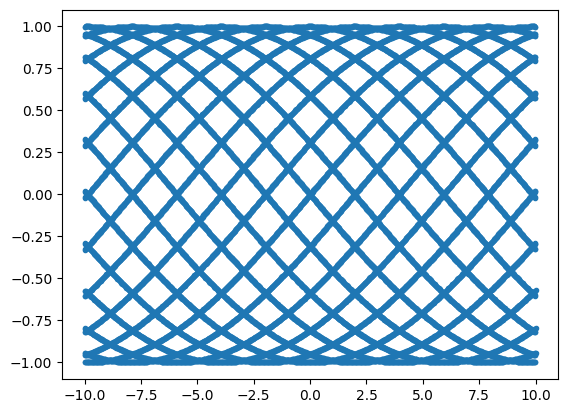

In [7]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(-10, 10, 0.001) #set x=0.01, x=0.001 and see what happens
y = np.sin(314*x)

plt.plot(x,y, marker='.', linestyle='none')
plt.show()

# Homework

The data in [populations.txt](https://lectures.scientific-python.org/_downloads/087d8fe936fcb7a4762b9850b932cf9e/populations.txt) describes the populations of hares, lynxes and carrots in northern Canada during 20 years. Get the data with ```np.loadtxt('https://lectures.scientific-python.org/_downloads/087d8fe936fcb7a4762b9850b932cf9e/populations.txt')``` and do the following exercises **without for-loops**.


Plot the population size of each species for each year on a single graph. Add legend and axis labels to the plot.

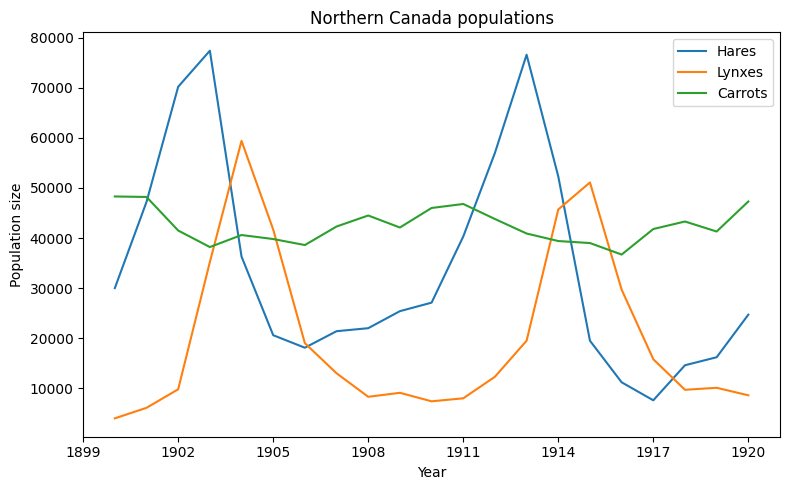

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FormatStrFormatter

data = np.loadtxt('https://lectures.scientific-python.org/_downloads/087d8fe936fcb7a4762b9850b932cf9e/populations.txt')
year    = data[:, 0].astype(int)
hares   = data[:, 1]
lynxes  = data[:, 2]
carrots = data[:, 3]

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(year, hares,   label='Hares')
ax.plot(year, lynxes,  label='Lynxes')
ax.plot(year, carrots, label='Carrots')

ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))

ax.set_xlabel('Year')
ax.set_ylabel('Population size')
ax.set_title('Northern Canada populations')
ax.legend()
plt.tight_layout()
plt.show()

Find which year each species had the largest population. Mark these years in the plot of populations.

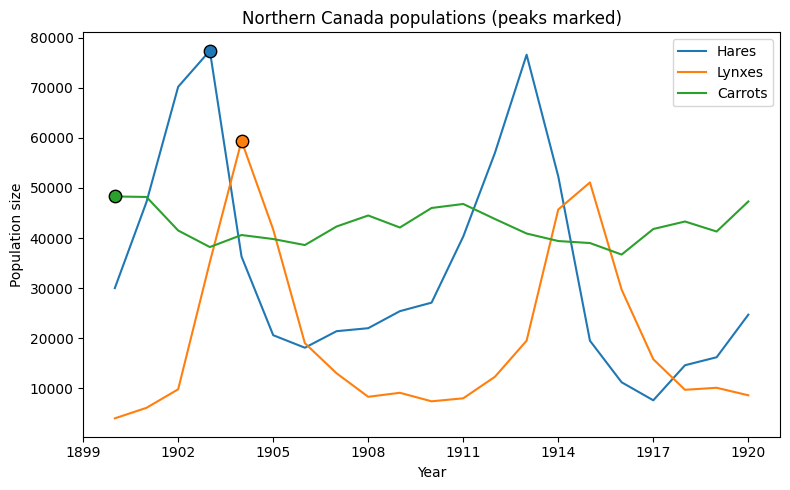

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FormatStrFormatter


data = np.loadtxt('https://lectures.scientific-python.org/_downloads/087d8fe936fcb7a4762b9850b932cf9e/populations.txt')
year    = data[:, 0].astype(int)
hares   = data[:, 1]
lynxes  = data[:, 2]
carrots = data[:, 3]


i_hare   = np.argmax(hares)
i_lynx   = np.argmax(lynxes)
i_carrot = np.argmax(carrots)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(year, hares,   label='Hares')
ax.plot(year, lynxes,  label='Lynxes')
ax.plot(year, carrots, label='Carrots')


ax.scatter(year[i_hare],   hares[i_hare],   s=80, zorder=5, edgecolor='k')
ax.scatter(year[i_lynx],   lynxes[i_lynx],  s=80, zorder=5, edgecolor='k')
ax.scatter(year[i_carrot], carrots[i_carrot], s=80, zorder=5, edgecolor='k')


ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))

ax.set_xlabel('Year')
ax.set_ylabel('Population size')
ax.set_title('Northern Canada populations (peaks marked)')
ax.legend()
plt.tight_layout()
plt.show()

Assuming total population of hares and lynxes is 100%, plot stacked bar graph showing ratio of each specis for each year in the period.

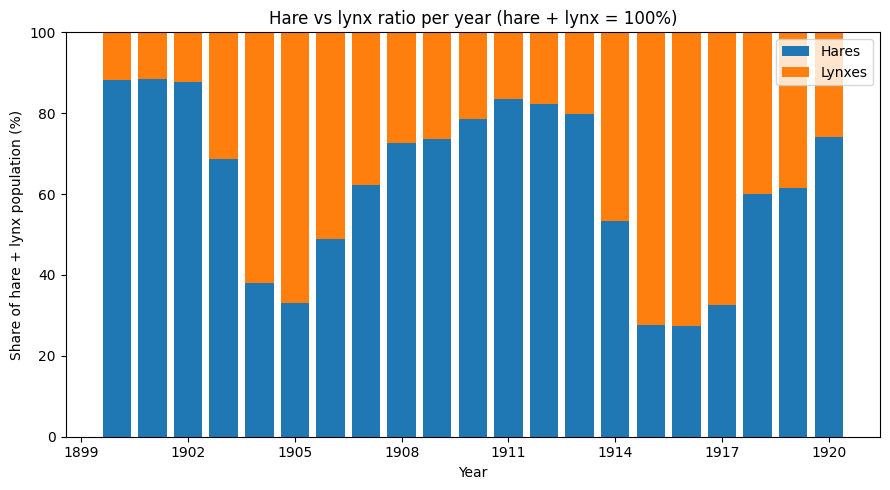

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FormatStrFormatter


data = np.loadtxt('https://lectures.scientific-python.org/_downloads/087d8fe936fcb7a4762b9850b932cf9e/populations.txt')
year   = data[:, 0].astype(int)
hares  = data[:, 1]
lynxes = data[:, 2]


total      = hares + lynxes
hare_ratio = hares / total * 100
lynx_ratio = lynxes / total * 100

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(year, hare_ratio, label='Hares',  color='C0')
ax.bar(year, lynx_ratio, bottom=hare_ratio, label='Lynxes', color='C1')

ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))

ax.set_xlabel('Year')
ax.set_ylabel('Share of hare + lynx population (%)')
ax.set_title('Hare vs lynx ratio per year (hare + lynx = 100%)')
ax.set_ylim(0, 100)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

Find the mean and std of the populations of each species. Plot the historgam of population for each species and show mean values with vertical line. Show each histogram in a separate plot. Arrange 3 plots in a row.

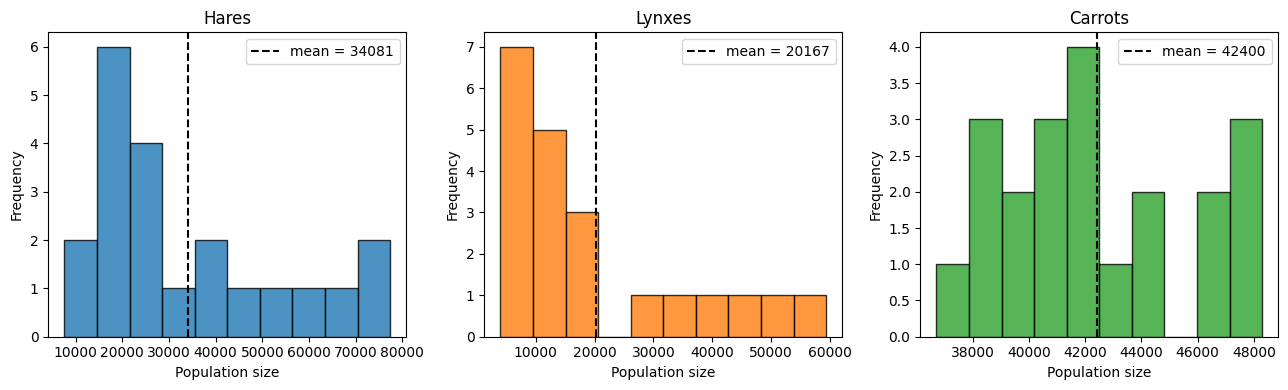

In [31]:
import numpy as np
import matplotlib.pyplot as plt

data = np.loadtxt('https://lectures.scientific-python.org/_downloads/087d8fe936fcb7a4762b9850b932cf9e/populations.txt')

year    = data[:, 0].astype(int)
hares   = data[:, 1]
lynxes  = data[:, 2]
carrots = data[:, 3]


populations = data[:, 1:4]
means = populations.mean(axis=0)
stds  = populations.std(axis=0)

names = ['Hares', 'Lynxes', 'Carrots']
#for name, m, s in zip(names, means, stds):  \
#    print(f"{name:8s}: mean = {m:9.1f}, std = {s:8.1f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].hist(hares,   bins=10, color='C0', edgecolor='k', alpha=0.8)
axes[1].hist(lynxes,  bins=10, color='C1', edgecolor='k', alpha=0.8)
axes[2].hist(carrots, bins=10, color='C2', edgecolor='k', alpha=0.8)

axes[0].axvline(means[0], color='k', linestyle='--', label=f'mean = {means[0]:.0f}')
axes[1].axvline(means[1], color='k', linestyle='--', label=f'mean = {means[1]:.0f}')
axes[2].axvline(means[2], color='k', linestyle='--', label=f'mean = {means[2]:.0f}')

for ax, name in zip(axes, names):
    ax.set_title(name)
    ax.set_xlabel('Population size')
    ax.set_ylabel('Frequency')
    ax.legend()

plt.tight_layout()
plt.show()

Find which species (hares or lynxes) has the largest population for each year. Print the result as [H, H, L, H, ...]. Plot a pie chart showing the ratio of "H" and "L" values.

[np.str_('H'), np.str_('H'), np.str_('H'), np.str_('H'), np.str_('L'), np.str_('L'), np.str_('L'), np.str_('H'), np.str_('H'), np.str_('H'), np.str_('H'), np.str_('H'), np.str_('H'), np.str_('H'), np.str_('H'), np.str_('L'), np.str_('L'), np.str_('L'), np.str_('H'), np.str_('H'), np.str_('H')]
H: 15, L: 6


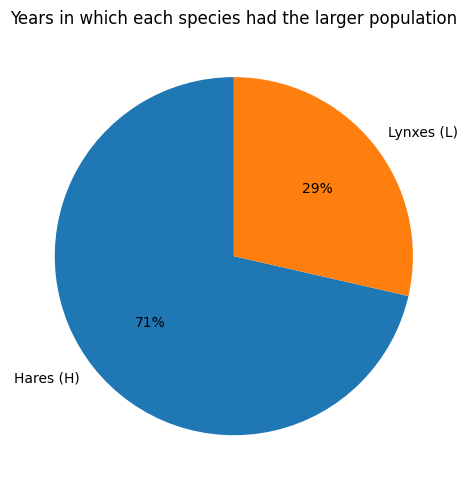

In [32]:
import numpy as np
import matplotlib.pyplot as plt


data = np.loadtxt('https://lectures.scientific-python.org/_downloads/087d8fe936fcb7a4762b9850b932cf9e/populations.txt')
year   = data[:, 0].astype(int)
hares  = data[:, 1]
lynxes = data[:, 2]

labels = np.where(hares > lynxes, 'H', 'L')
print(list(labels))


h_count = np.count_nonzero(labels == 'H')
l_count = np.count_nonzero(labels == 'L')
print(f"H: {h_count}, L: {l_count}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.pie([h_count, l_count], labels=['Hares (H)', 'Lynxes (L)'],
       autopct='%1.0f%%', colors=['C0', 'C1'], startangle=90)
ax.set_title('Years in which each species had the larger population')
plt.tight_layout()
plt.show()

Plot the change in the hare population and in the lynx population for each year. Find the correlation coefficient between the both time series.

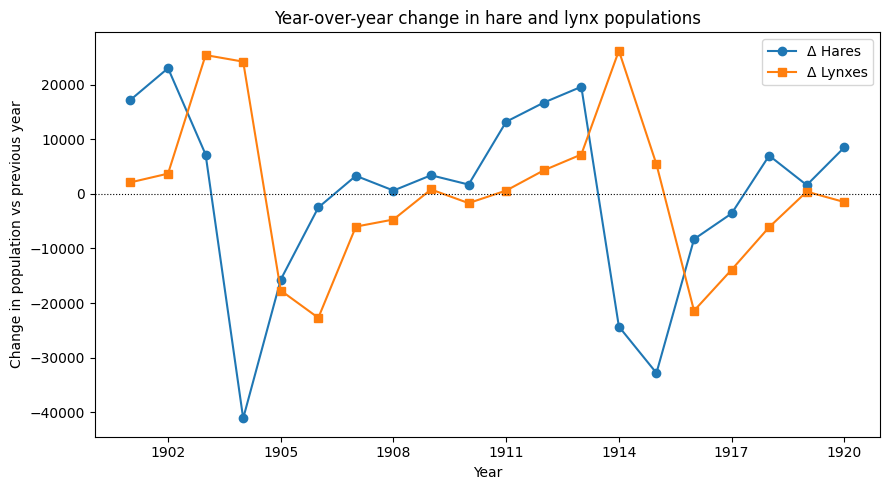

Correlation of year-to-year changes (hares vs lynxes): r = -0.178
Correlation of raw populations (hares vs lynxes):     r = 0.072


In [33]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FormatStrFormatter

data = np.loadtxt('https://lectures.scientific-python.org/_downloads/087d8fe936fcb7a4762b9850b932cf9e/populations.txt')

year   = data[:, 0].astype(int)
hares  = data[:, 1]
lynxes = data[:, 2]


d_hares  = np.diff(hares)
d_lynxes = np.diff(lynxes)
year_mid = year[1:]


fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(year_mid, d_hares,  marker='o', label='Δ Hares')
ax.plot(year_mid, d_lynxes, marker='s', label='Δ Lynxes')
ax.axhline(0, color='k', linewidth=0.8, linestyle=':')

ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))

ax.set_xlabel('Year')
ax.set_ylabel('Change in population vs previous year')
ax.set_title('Year-over-year change in hare and lynx populations')
ax.legend()
plt.tight_layout()
plt.show()


r_changes = np.corrcoef(d_hares, d_lynxes)[0, 1]
print(f"Correlation of year-to-year changes (hares vs lynxes): r = {r_changes:.3f}")

r_levels = np.corrcoef(hares, lynxes)[0, 1]
print(f"Correlation of raw populations (hares vs lynxes):     r = {r_levels:.3f}")

Using a scatter plot, show the population of hares vs lynxes by year (each point corresponds to a particular year, and the point coordinates correspond to the population of the two species in that year).

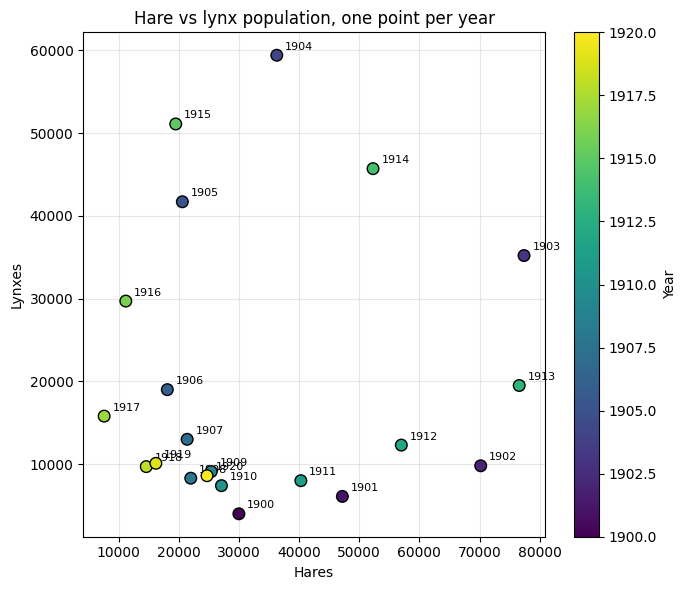

In [34]:
import numpy as np
import matplotlib.pyplot as plt

data = np.loadtxt('https://lectures.scientific-python.org/_downloads/087d8fe936fcb7a4762b9850b932cf9e/populations.txt')

year   = data[:, 0].astype(int)
hares  = data[:, 1]
lynxes = data[:, 2]

fig, ax = plt.subplots(figsize=(7, 6))

sc = ax.scatter(hares, lynxes, c=year, cmap='viridis', s=70, edgecolor='k', zorder=5)


for i in range(len(year)):
    ax.annotate(str(year[i]), (hares[i], lynxes[i]),
                textcoords='offset points', xytext=(6, 4), fontsize=8)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label('Year')

ax.set_xlabel('Hares')
ax.set_ylabel('Lynxes')
ax.set_title('Hare vs lynx population, one point per year')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Assume the population of hares in 1920 is unknown. Suggest a way to estimate this value. Compare an estimated value
with the true value and print a ratio of the error to the true value.

In [35]:
import numpy as np

data = np.loadtxt('https://lectures.scientific-python.org/_downloads/087d8fe936fcb7a4762b9850b932cf9e/populations.txt')

year   = data[:, 0].astype(int)
hares  = data[:, 1]

mask     = year != 1920
year_fit = year[mask]
hare_fit = hares[mask]

# Linear regression
slope, intercept = np.polyfit(year_fit, hare_fit, 1)
hare_pred = slope * 1920 + intercept

hare_true = hares[year == 1920][0]
error_ratio = (hare_pred - hare_true) / hare_true

print(f"True 1920 hares   : {hare_true:10.0f}")
print(f"Predicted 1920    : {hare_pred:10.1f}")
print(f"Error (pred-true) : {hare_pred - hare_true:10.1f}")
print(f"Error / true      : {error_ratio:10.3f}  ({error_ratio*100:.1f}%)")

True 1920 hares   :      24700
Predicted 1920    :    19775.8
Error (pred-true) :    -4924.2
Error / true      :     -0.199  (-19.9%)


### Let's practice: k-means clustering

<img src="https://media.geeksforgeeks.org/wp-content/uploads/20250103121010720223/Kmeans-implementation.png" width="800"/>

Входные данные в алгоритм: выборка, число кластеров, критерий остановки

Описание алгоритма:
* задаем начальное положение центров кластеров
* пока не выполнен критерий остановки:
  * распределяем точки к ближайшему центру
  * пересчитываем положения центров кластеров как центры масс образовавшихся кластеров

В качестве критерия остановки можно использовать малось изменения суммарной внутрикластерной дисперсии (суммы квадратов расстояний от каждой точки до центра ее кластера) и количество итераций.

### Датасет MNIST

Датасет MNSIT содержит примеры рукописных цифр. Загрузим датасет и посмотрим на примеры

In [36]:
from sklearn.datasets import fetch_openml

#Загрузка может занять около минуты
images, labels = fetch_openml('mnist_784', return_X_y=True, as_frame=False)

```images``` - массив картинок размера 28х28, вытянутых в вектор размера 784. Всего в датасете 70К примеров картинок

In [37]:
images.shape

(70000, 784)

```labels``` - массив, в котором записано, какая цифра нарисована на каждой картинке картинке

In [38]:
labels.shape

(70000,)

Нарисуем пример одной из картинок:

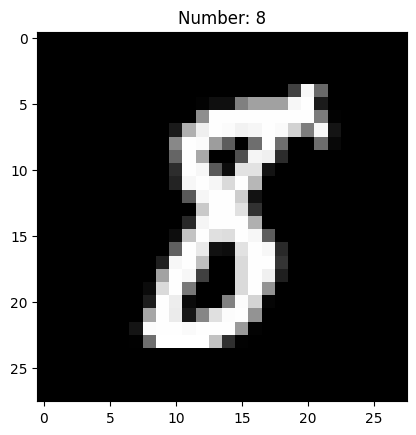

In [39]:
i = 125
plt.imshow(images[i].reshape(28, 28), cmap='Greys_r')
plt.title('Number: ' + labels[i])
plt.show()

Задание:

1) напишите функцию, реализующую алгоритм k-means.

Входом в функцию является

* массив NxM, где N -- число объектов, M -- число признаков объекта
* k -- число кластеров
* max_iter -- максимальное число итераций
* threshold -- критерий остановки (если на очередной итерации метода суммарное квадратичное отклонение изменяется меньше, чем на threshold, итерации прекращаются)

Выход:

* массив длины N, содержащий индексы кластеров от 0 до k-1
* суммарное квадратичное отклонение для полученного разбиения на кластеры

Постарайтесь обойтись минимальным количеством циклов в вашем коде.

2) Выделите 10 кластеров в датасете MNIST. Дайте интерпретацию каждому полученному кластеру (к какой цифре его можно отнести). Нарисуйте изображения, которые отвечают центрам кластеров. Посчитайте, сколько из точек кластера действительно являются той цифрой, к которой вы его отнесли (для этого сравните с массивом правильных ответов labels) и нарисуйте матрицу ошибок.

Загрузка MNIST...
Запуск k-means на 10000 точках...
WCSS = 390953.00

Соответствие кластер -> цифра (по большинству):
  кластер 0: цифра  1, точек   654, чистота 0.732
  кластер 1: цифра  0, точек   728, чистота 0.948
  кластер 2: цифра  2, точек   788, чистота 0.906
  кластер 3: цифра  1, точек  1027, чистота 0.582
  кластер 4: цифра  7, точек  1470, чистота 0.455
  кластер 5: цифра  8, точек   986, чистота 0.654
  кластер 6: цифра  4, точек  1529, чистота 0.356
  кластер 7: цифра  3, точек  1223, чистота 0.546
  кластер 8: цифра  6, точек   750, чистота 0.880
  кластер 9: цифра  5, точек   845, чистота 0.312


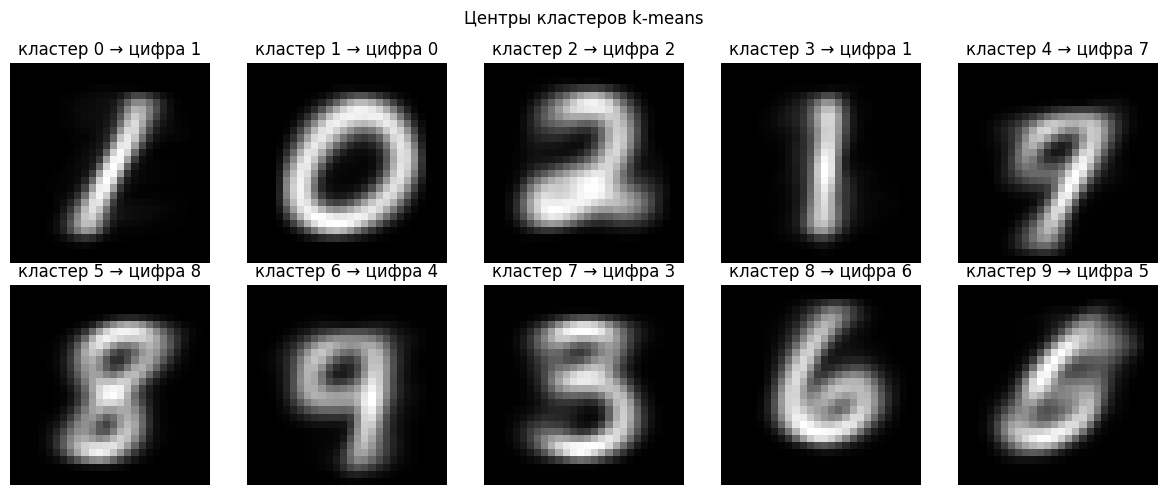

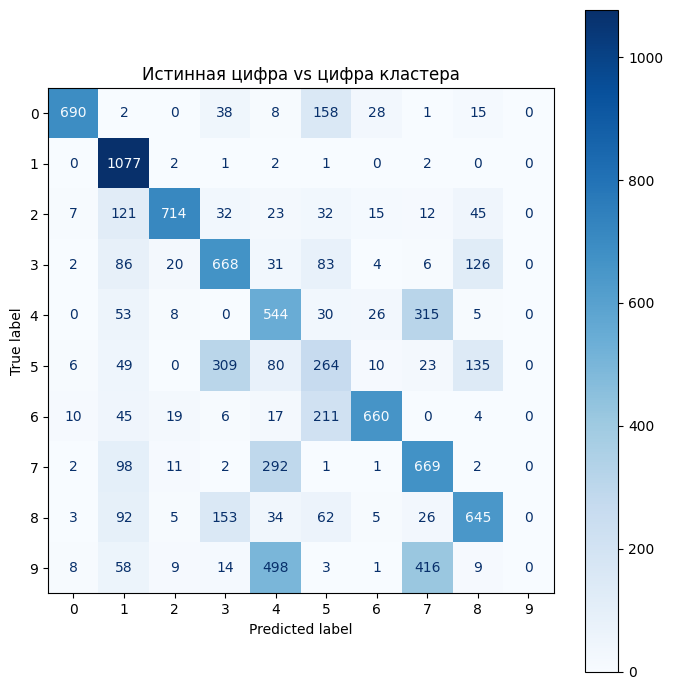


Средняя чистота кластеров : 0.637
Точность отображения      : 0.593


In [46]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


def kmeans(X, k, max_iter=100, threshold=1e-4, random_state=0):

    rng = np.random.default_rng(random_state)
    n, m = X.shape

    idx = rng.choice(n, size=k, replace=False)
    centers = X[idx].copy()

    prev_wcss = np.inf
    labels = np.zeros(n, dtype=int)

    for _ in range(max_iter):

        x2 = (X * X).sum(axis=1)[:, None]
        c2 = (centers * centers).sum(axis=1)[None, :]
        dists = x2 - 2.0 * X @ centers.T + c2
        np.maximum(dists, 0, out=dists)

        labels = dists.argmin(axis=1)
        wcss = dists[np.arange(n), labels].sum()

        if abs(prev_wcss - wcss) < threshold:
            break
        prev_wcss = wcss

        counts = np.bincount(labels, minlength=k)
        sums = np.zeros((k, m), dtype=X.dtype)
        np.add.at(sums, labels, X)
        nonempty = counts > 0
        centers[nonempty] = sums[nonempty] / counts[nonempty, None]

    return labels, wcss, centers


def main():
    print("Загрузка MNIST...")
    images, labels = fetch_openml('mnist_784', return_X_y=True, as_frame=False)
    X = images.astype(np.float32) / 255.0
    y = labels.astype(int)

    # Подвыборка для разумного времени работы и памяти
    rng = np.random.default_rng(0)
    n_sub = 10_000
    sub = rng.choice(X.shape[0], size=n_sub, replace=False)
    X_sub, y_sub = X[sub], y[sub]

    print(f"Запуск k-means на {n_sub} точках...")
    cluster_labels, wcss, centers = kmeans(
        X_sub, k=10, max_iter=100, threshold=1.0, random_state=0
    )
    print(f"WCSS = {wcss:.2f}")

    # Интерпретация кластеров: какой цифре соответствует каждый кластер

    mapping = {}
    purity = np.zeros(10)
    for c in range(10):
        pts = y_sub[cluster_labels == c]
        if pts.size:
            counts = np.bincount(pts, minlength=10)
            mapping[c] = int(counts.argmax())
            purity[c] = counts.max() / pts.size
        else:
            mapping[c] = -1

    print("\nСоответствие кластер -> цифра (по большинству):")
    for c in range(10):
        n_c = int((cluster_labels == c).sum())
        print(f"  кластер {c}: цифра {mapping[c]:2d}, "
              f"точек {n_c:5d}, чистота {purity[c]:.3f}")

    # Изображения центров кластероы
    fig, axes = plt.subplots(2, 5, figsize=(12, 5))
    for ax, c in zip(axes.ravel(), range(10)):
        ax.imshow(centers[c].reshape(28, 28), cmap='gray')
        ax.set_title(f"кластер {c} → цифра {mapping[c]}")
        ax.axis('off')
    plt.suptitle("Центры кластеров k-means")
    plt.tight_layout()
    plt.savefig('kmeans_centers.png', dpi=120)
    plt.show()

    # Матрица ошибок: истинная цифра vs цифра кластера

    pred_digit = np.array([mapping[c] for c in cluster_labels])

    cm = confusion_matrix(y_sub, pred_digit, labels=range(10))
    disp = ConfusionMatrixDisplay(cm, display_labels=range(10))
    fig, ax = plt.subplots(figsize=(7, 7))
    disp.plot(cmap='Blues', values_format='d', ax=ax)
    ax.set_title('Истинная цифра vs цифра кластера')
    plt.tight_layout()
    plt.savefig('kmeans_confusion.png', dpi=120)
    plt.show()


    accuracy = (pred_digit == y_sub).mean()
    print(f"\nСредняя чистота кластеров : {purity.mean():.3f}")
    print(f"Точность отображения      : {accuracy:.3f}")


if __name__ == '__main__':
    main()